# Machine Learning Assignment - 2
**M.Tech (AIML) - BITS Pilani**  
**Submission Deadline:** 08-Nov-2026  

---
### Assignment Objectives:
1. Implement 5 classification models on a chosen dataset ($\ge 12$ features, $\ge 500$ instances).
2. Calculate 6 evaluation metrics: Accuracy, AUC, Precision, Recall, F1 Score, MCC.
3. Save trained model artifacts (`.pkl`) and export `test_data.csv`.
4. Deploy an interactive Streamlit application.

## Step 1: Import Libraries and Setup

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, 
    recall_score, f1_score, matthews_corrcoef, 
    confusion_matrix, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

## Step 2: Dataset Generation / Loading
Creates a synthetic binary classification dataset with 14 features and 1,000 instances to meet BITS assignment requirements.

In [2]:
# Generate dataset with 14 features (> 12 required) and 1000 instances (> 500 required)
X_raw, y_raw = make_classification(
    n_samples=1000, 
    n_features=14, 
    n_informative=10, 
    n_redundant=4, 
    random_state=42
)

feature_names = [f"feature_{i+1}" for i in range(14)]
df = pd.DataFrame(X_raw, columns=feature_names)
df['target'] = y_raw

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (1000, 15)


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,target
0,0.495924,-1.812345,3.196149,-0.696229,0.523075,-1.322977,0.743918,6.010902,2.385628,2.117802,-0.939822,2.011043,-0.344327,-1.934951,1
1,-0.570054,-0.230386,-1.429152,0.911349,0.817405,0.731822,2.146293,1.194785,0.184613,0.529860,-1.087011,2.913697,-0.364111,-2.344174,1
2,-1.113095,-0.437266,3.902099,-0.446200,-1.339268,-1.400221,-0.857195,3.605523,1.159419,-1.024148,-1.020316,2.265334,1.028286,0.359856,1
3,-1.167282,-2.057240,1.535867,-0.806949,-0.144915,-0.177913,-3.940480,2.052896,-1.304378,-3.139003,-3.827841,1.480681,1.280291,2.115680,0
4,-2.451362,-2.618505,3.848032,-0.850767,-1.780405,-0.490021,-6.954542,1.876876,-1.201706,-4.749643,-3.882800,2.161740,0.808858,3.281528,0


## Step 3: Train-Test Split & Preprocessing

In [3]:
# Train-Test Split (80% Train, 20% Test)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['target'])

# Export test_data.csv required by assignment
test_df.to_csv("test_data.csv", index=False)
print("Saved test_data.csv successfully!")

X_train = train_df.drop(columns=['target'])
y_train = train_df['target']
X_test = test_df.drop(columns=['target'])
y_test = test_df['target']

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

os.makedirs("model", exist_ok=True)
joblib.dump(scaler, "model/scaler.pkl")

Saved test_data.csv successfully!


['model/scaler.pkl']

## Step 4: Model Training & Metric Calculation

In [4]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

metrics_list = []

for name, model in models.items():
    if name == "Decision Tree":
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]
    else:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Save model artifact
    file_name = name.lower().replace(" ", "_")
    joblib.dump(model, f"model/{file_name}.pkl")

    # Metrics
    metrics_list.append({
        "ML Model Name": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "AUC": round(roc_auc_score(y_test, y_proba), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1": round(f1_score(y_test, y_pred), 4),
        "MCC": round(matthews_corrcoef(y_test, y_pred), 4)
    })

metrics_df = pd.DataFrame(metrics_list)
print(metrics_df.to_string())

            ML Model Name  Accuracy     AUC  Precision  Recall      F1     MCC
0     Logistic Regression     0.850  0.9285     0.8646    0.83  0.8469  0.7006
1           Decision Tree     0.830  0.8663     0.8511    0.80  0.8247  0.6612
2                     KNN     0.950  0.9865     0.9500    0.95  0.9500  0.9000
3             Naive Bayes     0.835  0.9142     0.8602    0.80  0.8290  0.6716
4  Support Vector Machine     0.945  0.9847     0.9238    0.97  0.9463  0.8911


c:\Users\saiha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## Step 5: Visualizing Results

C:\Users\saiha\AppData\Local\Temp\ipykernel_6836\288876185.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x="ML Model Name", y="MCC", palette="Blues_d")


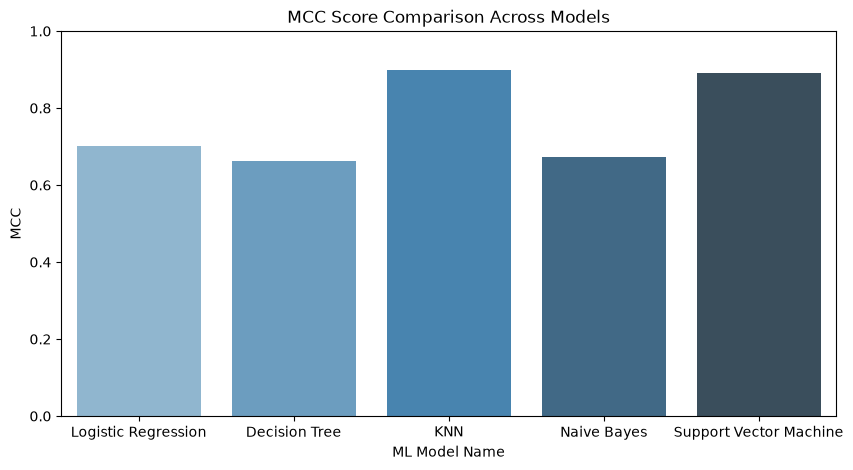

In [5]:
plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_df, x="ML Model Name", y="MCC", palette="Blues_d")
plt.title("MCC Score Comparison Across Models")
plt.ylim(0, 1)
plt.show()